# Классификация обращений

Научим модель выбирать отдел по сообщению студента. Сравним два способа представить текст — слова и символьные фрагменты — и посмотрим, какие обращения вызывают ошибки.

Начнём с простой точки отсчёта: насколько полезно всегда отвечать одной категорией? Затем обучим классификатор и сравним его результат с этим правилом.

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## Данные и сравнение

Используем корпус обращений из первой работы. Готовые части train, validation и test находятся в столбце `split`; `group_id` связывает перефразировки одной ситуации.

Модели по словам и символам будут обучаться на одном train. Для выбора используем macro-F1 на validation; при равенстве оставляем вариант words. К test перейдём после выбора. На этом наборе уже не будем подбирать настройки.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv(DATA / "requests.csv", keep_default_na=False)
train = df[df["split"].eq("train")].copy()
valid = df[df["split"].eq("validation")].copy()
test = df[df["split"].eq("test")].copy()
labels = sorted(df["label"].unique())
print({k: len(v) for k, v in {"train": train, "validation": valid, "test": test}.items()})

{'train': 360, 'validation': 120, 'test': 120}


### Как читать предсказания

В маленьком примере ниже известны настоящие категории и три ответа воображаемого классификатора. Найдите ошибку до запуска. Какую долю сообщений он направил правильно?

In [3]:
demo_true = np.array(["it", "library", "library"])
demo_pred = np.array(["it", "it", "library"])
display(pd.DataFrame({"true":demo_true, "predicted":demo_pred,
                      "correct":demo_true == demo_pred}))
print("Доля верных ответов:", np.mean(demo_true == demo_pred))

,true,predicted,correct
0,it,it,True
1,library,it,False
2,library,library,True


Доля верных ответов: 0.6666666666666666


Правильны два ответа из трёх. Ошибочное библиотечное обращение попало в ИТ. Дальше будем получать такие предсказания от обученной модели и смотреть не только на общий процент, но и на ошибки по категориям.

## 1. Разделяем ситуации, а не перефразировки

Проверьте, что одна группа не встречается сразу в двух частях корпуса. Сохраните множества `group_id` для train, validation и test в словарь `groups`, затем найдите пересечения каждой пары.

Посмотрите на число примеров каждой категории в каждой части. Все ли шесть отделов представлены? Почему пустого пересечения идентификаторов строк было бы недостаточно для проверки этого корпуса?

In [4]:
parts = {"train": train, "validation": valid, "test": test}
groups = {name: set(part["group_id"]) for name, part in parts.items()}
assert groups["train"].isdisjoint(groups["validation"])
assert groups["train"].isdisjoint(groups["test"])
assert groups["validation"].isdisjoint(groups["test"])
for name, part in parts.items():
    assert set(part["label"]) == set(labels)
    print(name, part["label"].value_counts().to_dict())

train {'it': 60, 'library': 60, 'dormitory': 60, 'study': 60, 'admission': 60, 'scholarship': 60}
validation {'it': 20, 'library': 20, 'dormitory': 20, 'study': 20, 'admission': 20, 'scholarship': 20}
test {'it': 20, 'library': 20, 'dormitory': 20, 'study': 20, 'admission': 20, 'scholarship': 20}


In [5]:
assert set(groups) == {"train", "validation", "test"}
assert len(set.union(*groups.values())) == df["group_id"].nunique()

В частях 72, 24 и 24 группы, то есть 360, 120 и 120 строк. Между частями нет общих групп. Проверка только id пропустила бы утечку через разные стилистические варианты одной ситуации.

## 2. От трёх документов к TF-IDF

Для начала возьмём три коротких текста из лекции. Обучите на них `toy_vectorizer`, сохраните матрицу в `toy_matrix` и выведите словарь, IDF и матрицу. Маленький результат удобно показать через `toarray()`, чтобы видеть каждую координату.

Проверьте столбец «книга»: слово дважды встретилось в первой строке, но df по всему набору равно 2. Объясните различие этих счётчиков. Сопоставьте первый нормированный вектор с ручным расчётом.

Большая матрица основного корпуса останется разреженной; её целиком переводить в `toarray()` не нужно.

In [6]:
toy = ["книга книга библиотека", "книга продление", "общежитие оплата"]
toy_vectorizer = TfidfVectorizer(smooth_idf=True, norm="l2", sublinear_tf=False)
toy_matrix = toy_vectorizer.fit_transform(toy)
print(toy_vectorizer.get_feature_names_out())
print("IDF:", toy_vectorizer.idf_.round(6))
display(pd.DataFrame(toy_matrix.toarray(), columns=toy_vectorizer.get_feature_names_out()))

['библиотека' 'книга' 'общежитие' 'оплата' 'продление']
IDF: [1.693147 1.287682 1.693147 1.693147 1.693147]


,библиотека,книга,общежитие,оплата,продление
0,0.549351,0.835592,0.000000,0.000000,0.000000
1,0.000000,0.605349,0.000000,0.000000,0.795961
2,0.000000,0.000000,0.707107,0.707107,0.000000


In [7]:
assert toy_matrix.shape == (3, 5)
assert np.allclose(np.asarray(toy_matrix.multiply(toy_matrix).sum(axis=1)).ravel(), 1)
book_index = toy_vectorizer.vocabulary_["книга"]
assert np.isclose(toy_vectorizer.idf_[book_index], np.log(4 / 3) + 1)

IDF «книги» около 1,2877; у слов с df=1 около 1,6931. Первая строка после L2 имеет ненулевые координаты 0,549351 и 0,835592. Вопрос к студенту: почему сумма этих чисел не равна 1, хотя длина вектора равна 1?

## 3. Постоянный ответ как baseline

Обучите на train `DummyClassifier(strategy="most_frequent")`. Он будет возвращать одну категорию независимо от сообщения. Проверьте его на validation.

Напишите `score_predictions`, возвращающую словарь с ключами `accuracy` и `macro_f1`. Для F1 передавайте весь список `labels` и `zero_division=0`, чтобы одинаково учитывать все категории даже при отсутствии предсказаний некоторых из них. Результат baseline сохраните в `baseline_scores`.

Сколько правильных ответов можно было ожидать по распределению классов? Почему macro-F1 получилась заметно ниже accuracy?

In [8]:
def score_predictions(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)}

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(train), 1)), train["label"])
baseline_pred = baseline.predict(np.zeros((len(valid), 1)))
baseline_scores = score_predictions(valid["label"], baseline_pred)
print(baseline_scores)

{'accuracy': 0.16666666666666666, 'macro_f1': 0.047619047619047616}


In [9]:
assert 0 <= baseline_scores["accuracy"] <= 1
assert 0 <= baseline_scores["macro_f1"] <= 1

При равных шести категориях accuracy=1/6≈0,1667, macro-F1=1/21≈0,0476. Для единственной предсказываемой категории F1=2/7, для остальных — 0. Поэтому среднее по шести классам невелико.

## 4. Слова и символы

Постройте два Pipeline с одной и той же логистической регрессией. В words используйте `TfidfVectorizer(ngram_range=(1,2), max_features=5000)`. В chars — `TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), max_features=5000)`. Классификатор в обоих случаях: `LogisticRegression(C=1, max_iter=1000, random_state=42)`.

Обучите оба варианта на train и сравните их на validation. Сохраните конвейеры в `models`, оценки в `validation_scores`, имя выбранного варианта в `selected_name`, сам конвейер в `selected`. Основной критерий — macro-F1; при равенстве выбираем words.

Какой тип различий между обращениями может лучше сохранять символьное представление? Приведите пару словоформ или опечатку в качестве примера.

In [10]:
models = {
    "words": Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
                       ("clf", LogisticRegression(C=1, max_iter=1000, random_state=42))]),
    "chars": Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=5000)),
                       ("clf", LogisticRegression(C=1, max_iter=1000, random_state=42))]),
}
validation_scores = {}
for name, model in models.items():
    model.fit(train["text"], train["label"])
    validation_scores[name] = score_predictions(valid["label"], model.predict(valid["text"]))
selected_name = "chars" if validation_scores["chars"]["macro_f1"] > validation_scores["words"]["macro_f1"] else "words"
selected = models[selected_name]
display(pd.DataFrame(validation_scores).T)
print("Выбран:", selected_name)

,accuracy,macro_f1
words,0.450000,0.412048
chars,0.741667,0.742991


Выбран: chars


In [11]:
assert set(models) == {"words", "chars"}
assert selected_name in models
assert selected is models[selected_name]
assert all(0 <= s["macro_f1"] <= 1 for s in validation_scores.values())

В исходном запуске words даёт validation accuracy 0,45 и macro-F1≈0,4120; chars — около 0,7417 и 0,7430. Выбран chars. Сравнение объясняет результат этого корпуса; для другой коллекции порядок может измениться.

## 5. Где модель ошиблась

Примените выбранный конвейер к test, сохраните предсказания в `pred_test`, а метрики — в `test_scores`. Постройте матрицу ошибок: настоящие классы по строкам, предсказанные по столбцам.

Создайте таблицу `errors` с ошибочными обращениями. Выберите до пяти разных `group_id` для подробного разбора. Если ошибок меньше, разберите доступные и добавьте отдельные контрольные сообщения, не меняя модель.

Сравните несколько вариантов одной ошибочной группы. Ошибка сохраняется при перефразировании или появляется только в части строк? Проверьте также три контрольных входа: пустую строку, «жжжжжжжжж» и «Не открывается виртуальная комната конференции». Что определяет ответ, когда текст не даёт ни одного известного признака?

{'accuracy': 0.7916666666666666, 'macro_f1': 0.7651970897407003}
              precision    recall  f1-score   support

   admission       0.80      1.00      0.89        20
   dormitory       1.00      1.00      1.00        20
          it       0.62      1.00      0.77        20
     library       0.71      0.50      0.59        20
 scholarship       1.00      1.00      1.00        20
       study       0.56      0.25      0.34        20

    accuracy                           0.79       120
   macro avg       0.78      0.79      0.77       120
weighted avg       0.78      0.79      0.77       120



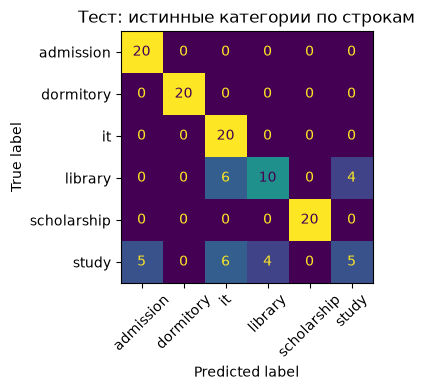

,group_id,text,label,predicted
190,library-19,Не могу найти монографию в списке доступной ли...,library,it
195,library-20,Мне нужна помощь в подборе источников для курс...,library,it
385,study-18,Когда откроется запись на повторный зачёт?,study,it
390,study-19,Как исправить ошибку в зачётной ведомости?,study,it
395,study-20,Где опубликован график экзаменационной сессии?,study,admission


[('', 'it'), ('жжжжжжжжж', 'it'), ('Не открывается виртуальная комната конференции', 'it')]


In [12]:
pred_test = selected.predict(test["text"])
test_scores = score_predictions(test["label"], pred_test)
print(test_scores)
print(classification_report(test["label"], pred_test, labels=labels, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test["label"], pred_test, labels=labels, xticks_rotation=45, colorbar=False)
plt.title("Тест: истинные категории по строкам")
plt.tight_layout(); plt.show()
errors = test.assign(predicted=pred_test).loc[lambda x: x["label"].ne(x["predicted"])]
display(errors.drop_duplicates("group_id").head(5)[["group_id", "text", "label", "predicted"]])
control = ["", "жжжжжжжжж", "Не открывается виртуальная комната конференции"]
print(list(zip(control, selected.predict(control))))

In [13]:
assert len(pred_test) == len(test)
assert set(pred_test) <= set(labels)
assert len(errors) == int(np.sum(test["label"].to_numpy() != pred_test))

В исходном результате неверны 25 из 120 строк: test accuracy≈0,7917, macro-F1≈0,7652. Ошибки относятся к library-19/20 и study-18/19/20. Каждую группу полезно сначала прочитать как ситуацию, а затем посмотреть различия формулировок.

## Разбор работы

Символьный вариант лучше словного на validation и потому выбран для test. Итоговая accuracy≈0,7917, macro-F1≈0,7652; постоянный baseline заметно слабее.

Две библиотечные группы содержат вопросы о монографии и подборе источников для курсовой. Все варианты library-19 направлены в ИТ. В library-20 один вариант направлен в ИТ, четыре — в учебный процесс. Среди учебных обращений ошибочны вопросы о повторном зачёте, исправлении ведомости и графике сессии. В study-18 один вариант направлен в ИТ и четыре — в библиотеку; в study-19 все пять — в ИТ; в study-20 все пять — в поступление. Это разные ситуации, хотя каждая представлена несколькими вариантами.

Можно исследовать, какие фрагменты активировались в этих сообщениях и какие похожие примеры были в train. Гипотеза о влиянии слова «ошибка» проверяется по признакам и дополнительным контролируемым примерам; само его присутствие ещё не объясняет решение.

На защите попросите пройти путь одного сообщения через vectorizer и классификатор. Затем предложите представить, что vectorizer заново обучили перед test: студент должен объяснить изменение словаря/IDF и нарушение соответствия обученным коэффициентам.

Показательная пара из library-20: исходная просьба о подборе источников получает it, а та же просьба с «Здравствуйте!» — study. Добавление приветствия изменило ответ этой модели, хотя категория ситуации осталась библиотечной. На таком примере удобно обсуждать устойчивость к формулировке.

Пустая строка и «жжжжжжжжж» дают нулевые векторы. При x=0 линейные оценки равны смещениям b. В обученном символьном классификаторе наибольшее смещение у it, поэтому оба входа получают эту метку. Текст о виртуальной комнате тоже отнесён к it, но содержит 64 ненулевых признака: его оценка учитывает и признаки, и смещения.

В примере library-20 исходная строка оканчивается точкой. При её удалении предсказание меняется с it на study. Поэтому буквальные диагностические входы нужно сохранять с пунктуацией; это дополнительная проверка чувствительности, отдельно от основных метрик корпуса.